In [9]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [29]:
import sklearn.preprocessing as preproc
import seaborn as sns
import matplotlib.pyplot as plt

In [30]:
import yfinance as yf

# Define the ticker symbol for S&P 500 (^GSPC)
# For example, https://finance.yahoo.com/quote/%5EGSPC/history/?period1=1569174385&period2=1727027123
ticker_symbol = "AAPL"

# Download historical data (adjust the period as needed, e.g., '1mo', '1y', 'max')
data = yf.download(
    ticker_symbol,
    start="2016-10-08",
    end="2026-10-09",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)

# Convert Date from index to a regular column
data = data.reset_index()

# Remove the label displayed above the column names
data.columns.name = None

# Save the data to a CSV file
data.to_csv('AAPL_historical_data.csv')

print("Data downloaded and saved as AAPL_historical_data.csv")

Data downloaded and saved as AAPL_historical_data.csv


In [31]:
data.to_csv(
    "AAPL_historical_data.csv",
    index=False
)

print("Dataset saved successfully.")
print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())

Dataset saved successfully.
Dataset shape: (2513, 7)
Columns: ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [32]:
data.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-10-10,26.538971,29.012501,29.187500,28.680000,28.754999,144944000
1,2016-10-11,26.596144,29.075001,29.672501,29.049999,29.424999,256164000
2,2016-10-12,26.833969,29.334999,29.495001,29.187500,29.337500,150347200
3,2016-10-13,26.751648,29.245001,29.360001,28.930000,29.197500,140769600
4,2016-10-14,26.900291,29.407499,29.542500,29.282499,29.469999,142608800


In [33]:
# Preserve an unchanged copy of the downloaded dataset
data_original = data.copy()

In [34]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2513 entries, 0 to 2512
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       2513 non-null   datetime64[ns]
 1   Adj Close  2513 non-null   float64       
 2   Close      2513 non-null   float64       
 3   High       2513 non-null   float64       
 4   Low        2513 non-null   float64       
 5   Open       2513 non-null   float64       
 6   Volume     2513 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 137.6 KB


In [35]:
data.describe()

,Date,Adj Close,Close,High,Low,Open,Volume
count,2513,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2.513000e+03
mean,2021-10-07 13:46:17.715877376,134.567372,136.958811,138.329123,135.448595,136.820037,9.316546e+07
min,2016-10-10 00:00:00,24.298479,26.427500,26.920000,26.020000,26.642500,1.791060e+07
25%,2019-04-10 00:00:00,48.759979,51.117500,51.527500,50.672501,51.070000,5.451150e+07
50%,2021-10-06 00:00:00,138.752594,142.059998,143.520004,139.899994,142.059998,8.107720e+07
75%,2024-04-08 00:00:00,189.252701,191.559998,192.979996,189.910004,191.440002,1.136056e+08
max,2026-10-08 00:00:00,341.070007,341.070007,345.339996,338.750000,341.079987,4.479400e+08
std,NaN,82.203313,81.659155,82.451299,80.773683,81.555785,5.361629e+07


In [36]:
data.isnull().sum()

Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

In [40]:
data.duplicated().sum()

np.int64(0)

In [41]:
duplicate_dates = data["Date"].duplicated().sum()

print("Number of duplicated dates:", duplicate_dates)

Number of duplicated dates: 0


This graph shows how Apple’s adjusted share price changed over time. Adj Close was selected because it accounts for changes such as dividends and stock splits.

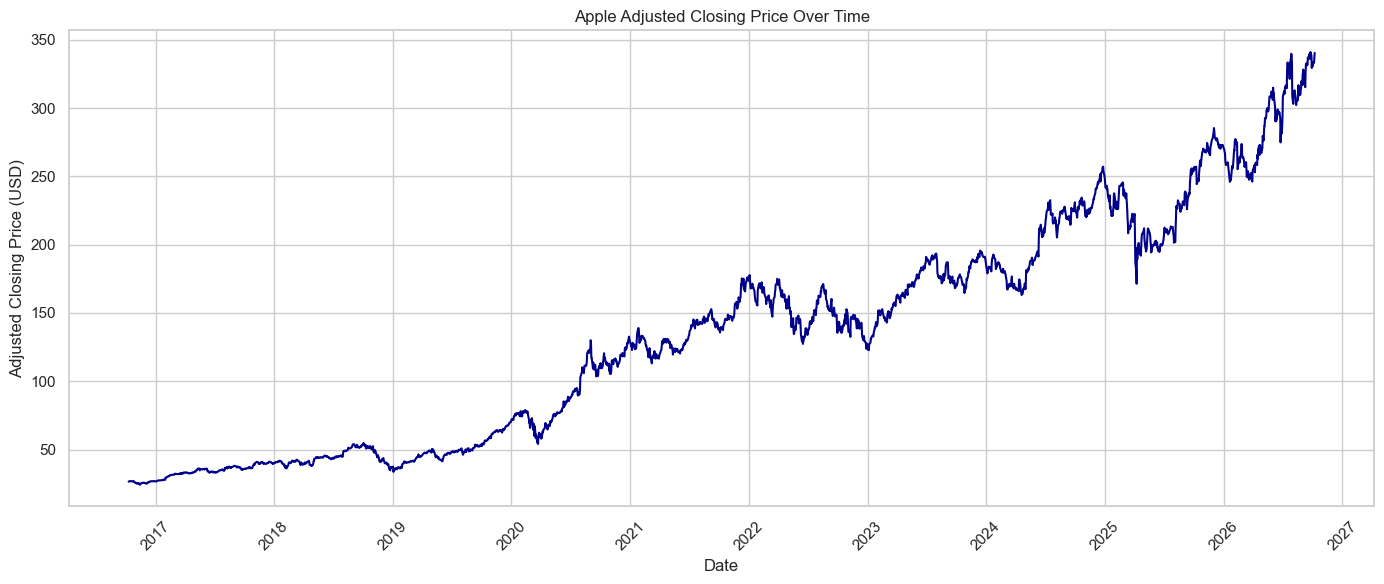

In [42]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 6))

plt.plot(
    data["Date"],
    data["Adj Close"],
    color="darkblue",
    linewidth=1.5
)

plt.title("Apple Adjusted Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The graph shows a strong upward trend in Apple’s adjusted closing price during the ten-year period. The price increased from approximately 25 dolares  to  more  than 340 dolares, although several temporary declines and periods of greater price variation can also be observed. This trend suggests that the original price series may not be stationary, but this will be confirmed later using the Augmented Dickey-Fuller test